# Q-Learning in FrozenLake

Q-Learning is a **model-free, off-policy reinforcement learning algorithm** that learns the optimal action-value function through interaction with an environment.

It is model-free because it does not require prior knowledge of the environment's transition probabilities or reward function. It is off-policy because it learns the optimal greedy policy while behavior may include exploratory actions.

The objective is to learn which action to take in each state to maximize the expected cumulative discounted reward.

## 1. Exploration vs. Exploitation

- **Exploitation:** Choose the action with the highest estimated Q-value.
- **Exploration:** Try actions to discover potentially better outcomes.

The ε-greedy policy balances both:

$$
a_t =
\begin{cases}
\text{random action}, & \text{with probability } \varepsilon,\\
\arg\max_a Q(s_t,a), & \text{with probability } 1-\varepsilon.
\end{cases}
$$

The exploration rate can decay over time:

$$
\varepsilon_{t+1}
=
\max(\varepsilon_{\min},d\varepsilon_t)
$$

Here, $d$ is the decay factor and $\varepsilon_{\min}$ is the minimum exploration rate.

## 2. Return and Action-Value Function

The discounted return is the total future reward, with later rewards weighted less:

$$
G_t = R_{t+1}+\gamma R_{t+2}+\gamma^2 R_{t+3}+\cdots
$$

Equivalently,

$$
G_t = R_{t+1}+\gamma G_{t+1}
$$

The action-value function under policy $\pi$ is:

$$
Q^\pi(s,a)
=
\mathbb{E}_\pi[G_t\mid S_t=s,A_t=a]
$$

The optimal action-value function is:

$$
Q^*(s,a)=\max_\pi Q^\pi(s,a)
$$

The optimal policy selects an action with the highest Q-value in the current state.

## 3. Deriving the Q-Learning Update

**Step 1: Bellman optimality equation**

The optimal action-value function satisfies:

$$
Q^*(s,a)
=
\mathbb{E}\left[
R_{t+1}+\gamma\max_{a'}Q^*(S_{t+1},a')
\right]
$$

**Step 2: Sample-based target**

After observing reward $r$ and next state $s'$, define the temporal-difference target:

$$
Y_t = r+\gamma\max_{a'}Q(s',a')
$$

**Step 3: Temporal-difference error**

The difference between the target and current estimate is:

$$
\delta_t = Y_t-Q(s,a)
$$

Substituting the target:

$$
\delta_t
=
r+\gamma\max_{a'}Q(s',a')-Q(s,a)
$$

**Step 4: Incremental update**

Move the current estimate toward the target using learning rate $\alpha$:

$$
Q_{\text{new}}(s,a)=Q(s,a)+\alpha\delta_t
$$

Substituting the TD error gives the Q-Learning update rule:

$$
\boxed{
Q(s,a)\leftarrow Q(s,a)+
\alpha\left[
r+\gamma\max_{a'}Q(s',a')-Q(s,a)
\right]
}
$$

## 4. Handling Terminal States

When the next state is terminal, there is no future value to bootstrap from. Introduce a mask $m$:

$$
m =
\begin{cases}
1, & \text{if the episode continues},\\
0, & \text{if the episode terminates}.
\end{cases}
$$

The complete update becomes:

$$
\boxed{
Q(s,a)\leftarrow Q(s,a)+\alpha
\left[
r+\gamma m\max_{a'}Q(s',a')-Q(s,a)
\right]
}
$$

In FrozenLake, reaching the goal gives reward $1$, while falling into a hole gives reward $0$. Both end the episode, so $m=0$ for either transition.

## 5. Q-Table Initialization

The Q-table stores the estimated value of every state-action pair. For FrozenLake, there are 16 states and 4 actions, so the table has dimensions $16 \times 4$.

Initially, all values are set to zero because the agent has no prior experience.

$$
Q(s,a)=0 \qquad \forall s,a
$$

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=False
)

n_states = env.observation_space.n
n_actions = env.action_space.n

print("Number of states:", n_states)
print("Number of actions:", n_actions)

Number of states: 16
Number of actions: 4


In [2]:
Q = np.zeros((n_states, n_actions))
print(Q)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


## 6. ε-Greedy Action Selection

The agent explores with probability $\varepsilon$ and exploits with probability $1-\varepsilon$.

During exploitation, if multiple actions share the maximum Q-value, we randomly select among them to avoid a fixed tie-breaking bias.

In [3]:
def choose_action(state, Q, epsilon):
    if np.random.random() < epsilon:
        return env.action_space.sample()  # Explore

    best_actions = np.flatnonzero(Q[state] == Q[state].max())
    return np.random.choice(best_actions)  # Exploit

## 7. Q-Learning Training

At each time step, the agent:

1. Selects an action using the ε-greedy policy.
2. Executes the action and observes the next state and reward.
3. Updates the corresponding Q-value using the Q-Learning rule.
4. Repeats until the episode terminates or is truncated.

We gradually reduce $\varepsilon$ to shift from exploration toward exploitation.

## Optional: GPU Availability

Tabular Q-Learning uses a small Q-table and simple numerical updates, so a GPU is generally unnecessary. However, GPU availability becomes more relevant when experimenting with neural-network-based methods such as DQN.

The following cell checks whether CUDA is available through PyTorch. Skip this section if you are only running tabular Q-Learning.

In [8]:
import torch

if torch.cuda.is_available():
    print("CUDA is available!")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available. CPU execution is fine for tabular Q-Learning.")

CUDA is available!
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [9]:
# Hyperparameters
num_episodes = 20_000
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.9995

episode_rewards = []
successes = []

for episode in range(num_episodes):
    state, info = env.reset()
    total_reward = 0

    while True:
        action = choose_action(state, Q, epsilon)

        next_state, reward, terminated, truncated, info = env.step(action)

        # No bootstrapping after an episode ends
        best_next_value = 0 if terminated or truncated else np.max(Q[next_state])

        td_target = reward + gamma * best_next_value
        td_error = td_target - Q[state, action]

        Q[state, action] += alpha * td_error

        state = next_state
        total_reward += reward

        if terminated or truncated:
            break

    episode_rewards.append(total_reward)
    successes.append(total_reward > 0)

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Training complete!")
print("Final epsilon:", round(epsilon, 4))
print("Success rate over last 500 episodes:",
      round(np.mean(successes[-500:]), 3))

Training complete!
Final epsilon: 0.01
Success rate over last 500 episodes: 0.992


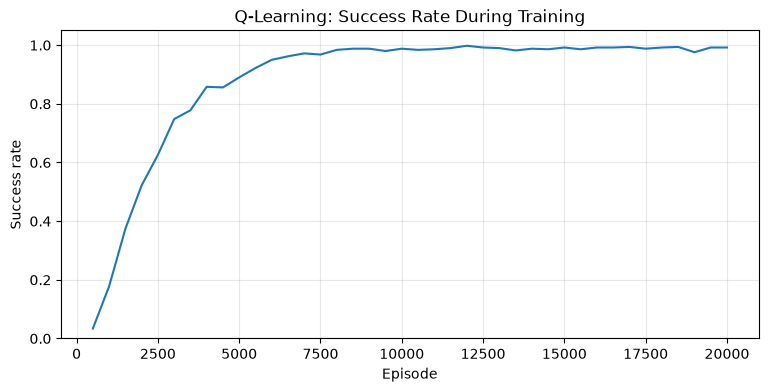

In [10]:
window = 500

success_rate = [
    np.mean(successes[i:i + window])
    for i in range(0, len(successes) - window + 1, window)
]

plt.figure(figsize=(9, 4))
plt.plot(
    np.arange(1, len(success_rate) + 1) * window,
    success_rate
)
plt.xlabel("Episode")
plt.ylabel("Success rate")
plt.title("Q-Learning: Success Rate During Training")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.show()

## 8. Learning Under Stochastic Transitions

So far, we used `is_slippery=False`, where movement is deterministic except at grid boundaries. Now we use `is_slippery=True`, where the agent may move in a direction different from the intended action.

This introduces uncertainty into the transition dynamics. We train a separate Q-table for this environment and compare its performance with the deterministic setting.

**Important:** The slippery environment needs its own training run; we should not reuse the deterministic Q-table as if it were learned under the same dynamics.

In [ ]:
# Create a separate slippery environment
slippery_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

Q_slippery = np.zeros((
    slippery_env.observation_space.n,
    slippery_env.action_space.n
))

num_episodes = 50,000
alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.9995

slippery_successes = []

for episode in range(num_episodes):
    state, info = slippery_env.reset()
    total_reward = 0

    while True:
        if np.random.random() < epsilon:
            action = slippery_env.action_space.sample()
        else:
            best_actions = np.flatnonzero(
                Q_slippery[state] == Q_slippery[state].max()
            )
            action = np.random.choice(best_actions)

        next_state, reward, terminated, truncated, info = (
            slippery_env.step(action)
        )

        next_value = (
            0 if terminated or truncated
            else np.max(Q_slippery[next_state])
        )

        Q_slippery[state, action] += alpha * (
            reward + gamma * next_value - Q_slippery[state, action]
        )

        state = next_state
        total_reward += reward

        if terminated or truncated:
            break

    slippery_successes.append(total_reward > 0)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Slippery training complete!")
print("Success rate over last 1,000 episodes:",
      round(np.mean(slippery_successes[-1000:]), 3))

Slippery training complete!
Success rate over last 1,000 episodes: 0.652


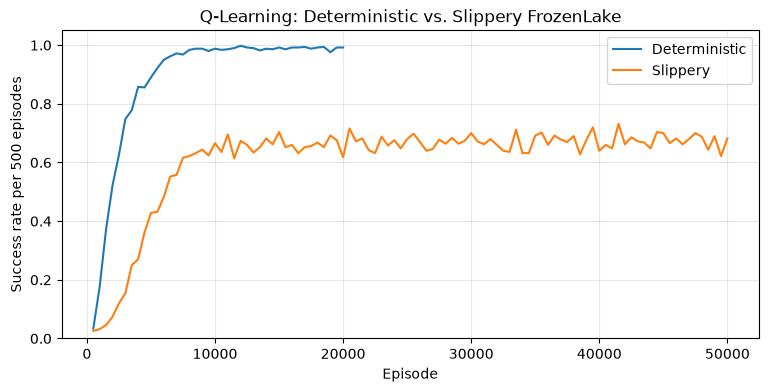

In [12]:
window = 500

def moving_success_rate(results, window):
    return [
        np.mean(results[i:i + window])
        for i in range(0, len(results) - window + 1, window)
    ]

det_rate = moving_success_rate(successes, window)
slip_rate = moving_success_rate(slippery_successes, window)

plt.figure(figsize=(9, 4))
plt.plot(
    np.arange(1, len(det_rate) + 1) * window,
    det_rate,
    label="Deterministic"
)
plt.plot(
    np.arange(1, len(slip_rate) + 1) * window,
    slip_rate,
    label="Slippery"
)

plt.xlabel("Episode")
plt.ylabel("Success rate per 500 episodes")
plt.title("Q-Learning: Deterministic vs. Slippery FrozenLake")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Observations

- **Deterministic environment:** Actions have predictable outcomes, making it easier to learn a reliable path to the goal.
- **Slippery environment:** Stochastic transitions can move the agent away from its intended direction, making success less predictable.
- **Learning performance:** Compare success rates over multiple episodes rather than relying on a single successful run.

The slippery setting illustrates why an agent must learn action values that account for uncertain outcomes, not just the intended direction of movement.

In [13]:
def evaluate_policy(env, Q, num_episodes=1000):
    successes = 0

    for _ in range(num_episodes):
        state, info = env.reset()

        while True:
            # Greedy action selection
            action = np.argmax(Q[state])

            state, reward, terminated, truncated, info = env.step(action)

            if terminated or truncated:
                successes += int(reward > 0)
                break

    return successes / num_episodes


deterministic_rate = evaluate_policy(env, Q)
slippery_rate = evaluate_policy(slippery_env, Q_slippery)

print(f"Deterministic success rate: {deterministic_rate:.3f}")
print(f"Slippery success rate: {slippery_rate:.3f}")

Deterministic success rate: 1.000
Slippery success rate: 0.730


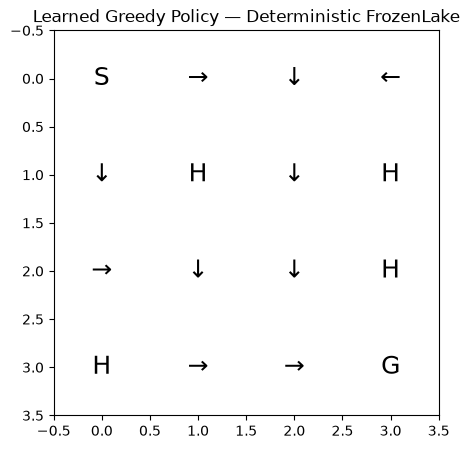

In [14]:
action_symbols = ["←", "↓", "→", "↑"]
desc = env.unwrapped.desc.astype("U1")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(np.zeros((4, 4)), cmap="Greys", vmin=0, vmax=1)

for state in range(n_states):
    row, col = divmod(state, 4)
    tile = desc[row, col]

    if tile == "H":
        symbol = "H"
    elif tile == "G":
        symbol = "G"
    elif tile == "S":
        symbol = "S"
    else:
        symbol = action_symbols[np.argmax(Q[state])]

    ax.text(col, row, symbol, ha="center", va="center", fontsize=18)

ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
ax.grid(which="minor", color="black")
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_title("Learned Greedy Policy — Deterministic FrozenLake")
plt.show()